# EXP002 — Systematic Error Analysis

Analyze the non-exact predictions from the completed EXP002 IAM test-set baseline.

**Baseline**
- Model: `microsoft/trocr-base-handwritten`
- Test samples: 1,480 usable IAM lines
- CER: 3.33%
- WER: 8.63%
- Exact Match: 56.89%
- Exact predictions: 842
- Non-exact predictions: 638

## Research Question

**RQ1: What types of recognition errors contribute most to TrOCR's incorrect predictions on IAM?**

This notebook creates a reproducible **targeted diagnostic sample** of:
- 50 highest-CER failures
- 50 randomly selected remaining failures
- 25 lowest-CER non-exact failures

Because severe and minor errors are deliberately oversampled, category percentages from the 125 reviewed samples should **not** be interpreted as the natural prevalence of error types across all 638 failures.


## 1. Project Setup

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()

if (cwd / "src").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "src").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not locate the project root. Open this notebook from "
        "trocr_beginner_project/ or trocr_beginner_project/notebooks/."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Python:", sys.executable)


Project root: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project
Python: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/.venv/bin/python


## 2. Load EXP002 Test Predictions

In [2]:
PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "exp002"
    / "iam_test"
    / "predictions.csv"
)

if not PREDICTIONS_PATH.exists():
    raise FileNotFoundError(
        f"EXP002 predictions were not found:\n{PREDICTIONS_PATH}"
    )

df = pd.read_csv(PREDICTIONS_PATH)

# Standardize the identifier column used by the EXP002 notebook.
if "sample" in df.columns and "id" not in df.columns:
    df = df.rename(columns={"sample": "id"})

required = {"id", "ground_truth", "prediction", "cer", "wer", "exact"}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

print("Predictions file:", PREDICTIONS_PATH)
print("Total samples:", len(df))
print("Columns:", df.columns.tolist())

df.head()


Predictions file: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp002/iam_test/predictions.csv
Total samples: 1480
Columns: ['id', 'ground_truth', 'prediction', 'cer', 'wer', 'exact']


,id,ground_truth,prediction,cer,wer,exact
0,m01-049-00,He rose from his breakfast-nook bench,He rose from his breakfast-nook bench,0.000000,0.000000,1
1,m01-049-01,"and came into the livingroom , where","and come into the European , where",0.305556,0.285714,0
2,m01-049-02,Heather and Steve stood aghast at,Heather and Neue stood again on,0.242424,0.500000,0
3,m01-049-03,"his entrance . He came , almost falling","his entrance . He came , album falling",0.102564,0.125000,0
4,m01-049-04,"forward in an ungainly shuffle , neck","found in an ungainly shuffle , neck",0.108108,0.142857,0


## 3. Verify EXP002 Baseline

In [3]:
total = len(df)
exact_count = int(df["exact"].sum())
non_exact_count = int((df["exact"] == 0).sum())

print("Total predictions :", total)
print("Exact matches     :", exact_count)
print("Non-exact         :", non_exact_count)
print()
print(f"Average CER       : {df['cer'].mean():.6f}")
print(f"Average WER       : {df['wer'].mean():.6f}")
print(f"Exact Match Rate  : {df['exact'].mean():.2%}")

# These assertions protect against accidentally loading n20/n50/n100 results.
assert total == 1480, f"Expected 1480 test samples, found {total}"
assert exact_count == 842, f"Expected 842 exact matches, found {exact_count}"
assert non_exact_count == 638, f"Expected 638 non-exact predictions, found {non_exact_count}"

print("\nEXP002 baseline verified successfully.")


Total predictions : 1480
Exact matches     : 842
Non-exact         : 638

Average CER       : 0.033293
Average WER       : 0.086293
Exact Match Rate  : 56.89%

EXP002 baseline verified successfully.


## 4. Identify the 638 Non-Exact Predictions

In [4]:
incorrect_df = df[df["exact"] == 0].copy()

print("Incorrect predictions:", len(incorrect_df))

incorrect_df[
    ["id", "ground_truth", "prediction", "cer", "wer"]
].head(10)


Incorrect predictions: 638


,id,ground_truth,prediction,cer,wer
1,m01-049-01,"and came into the livingroom , where","and come into the European , where",0.305556,0.285714
2,m01-049-02,Heather and Steve stood aghast at,Heather and Neue stood again on,0.242424,0.500000
3,m01-049-03,"his entrance . He came , almost falling","his entrance . He came , album falling",0.102564,0.125000
4,m01-049-04,"forward in an ungainly shuffle , neck","found in an ungainly shuffle , neck",0.108108,0.142857
5,m01-049-05,"thrust out , arms dangling loosely .","themwell , and , arms changing loosely .",0.388889,0.571429
7,m01-049-07,and walked on the very tips of,and talked on the very lips of,0.066667,0.285714
8,m01-049-08,his toes . He stretched his arms,his does . He sketched his arms,0.093750,0.285714
9,m01-049-10,drawing-in great breaths that,drawing-in good breaths that,0.137931,0.250000
10,m01-060-02,"forward . "" Isn't it a glorious thing ! Long a...","forward . "" Sn't it a glorious thing ! I say a...",0.134615,0.272727
13,m01-060-05,"Mind is at hand ! "" He turned beaming eyes","Mind is at hand ! "" He turned becoming eyes",0.047619,0.100000


## 5. Select 125 Samples for Manual Analysis

The selection is **non-overlapping and reproducible**:

| Group | Samples | Purpose |
|---|---:|---|
| Highest CER | 50 | Severe recognition failures |
| Random non-exact | 50 | Typical errors |
| Low-CER non-exact | 25 | Minor errors that still fail Exact Match |

`random_state=42` ensures the same random cases are selected whenever the notebook is rerun.


In [5]:
# 1) Highest-CER failures
high_cer = (
    incorrect_df
    .sort_values("cer", ascending=False)
    .head(50)
    .copy()
)
high_cer["selection_group"] = "high_cer"

# Remove selected rows before selecting the next group.
remaining = incorrect_df[
    ~incorrect_df["id"].isin(high_cer["id"])
].copy()

# 2) Lowest-CER failures that are still non-exact
low_cer = (
    remaining[remaining["cer"] > 0]
    .sort_values("cer", ascending=True)
    .head(25)
    .copy()
)
low_cer["selection_group"] = "low_cer"

remaining = remaining[
    ~remaining["id"].isin(low_cer["id"])
].copy()

# 3) Random sample from the remaining failures
random_errors = remaining.sample(
    n=min(50, len(remaining)),
    random_state=42
).copy()
random_errors["selection_group"] = "random"

analysis_df = pd.concat(
    [high_cer, random_errors, low_cer],
    ignore_index=True
)

assert len(analysis_df) == 125, f"Expected 125 samples, found {len(analysis_df)}"
assert analysis_df["id"].is_unique, "Duplicate samples detected!"

print(analysis_df["selection_group"].value_counts())
print("\nTotal selected:", len(analysis_df))
print("Unique IDs:", analysis_df["id"].nunique())


selection_group
high_cer    50
random      50
low_cer     25
Name: count, dtype: int64

Total selected: 125
Unique IDs: 125


## 6. Add Manual Annotation Columns

In [6]:
analysis_df["error_category"] = ""
analysis_df["image_quality"] = ""
analysis_df["handwriting_difficulty"] = ""
analysis_df["notes"] = ""

analysis_df = analysis_df[
    [
        "id",
        "ground_truth",
        "prediction",
        "cer",
        "wer",
        "selection_group",
        "error_category",
        "image_quality",
        "handwriting_difficulty",
        "notes",
    ]
]

analysis_df.head()


,id,ground_truth,prediction,cer,wer,selection_group,error_category,image_quality,handwriting_difficulty,notes
0,p03-033-04,"suppose , to meet me for supper somewhere ? "" ...","Surname , is met at the ROH Superior Adventure...",0.603774,0.833333,high_cer,,,,
1,m04-038-04,Dinas Motor Omnibus Co. to ask what had happen...,"Dennis Hunter Dravides , her , Her wish that h...",0.578947,1.000000,high_cer,,,,
2,p06-047-07,"his # prescription pad , and","his # # # if pressure script on paid , and",0.535714,1.166667,high_cer,,,,
3,p02-022-04,laid his hand on hers . Gay smiled at him,David Luis blamed on Nero . Glory reunited out...,0.487805,0.700000,high_cer,,,,
4,p06-030-08,you are satisfied . ',"you are rats "" pedal .",0.428571,0.800000,high_cer,,,,


## 7. Error Annotation Guide

### Error categories

Multiple categories are allowed. Separate them with a semicolon (`;`).

Use only these labels initially:

- `Character substitution`
- `Insertion`
- `Deletion`
- `Word substitution`
- `Spacing`
- `Punctuation`
- `Capitalization`
- `Possible handwriting ambiguity`
- `Possible image-quality issue`
- `Possible language-generation error`
- `Other`

Example:

```text
Character substitution;Possible handwriting ambiguity
```

### Image quality

Use:

```text
Good
Moderate
Poor
```

Only assign this after inspecting the actual IAM image.

### Handwriting difficulty

Use:

```text
Easy
Moderate
Difficult
```

Again, inspect the image rather than inferring difficulty from the prediction.

### Important

A plausible but incorrect word is **not automatically** a language-generation error. Use `Possible language-generation error` only as a cautious descriptive label when the prediction appears to be a plausible linguistic continuation/substitution.


## 8. Save the 125-Sample Analysis CSV

In [7]:
RESULTS_DIR = PROJECT_ROOT / "results" / "exp002"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ANALYSIS_PATH = RESULTS_DIR / "exp002_error_analysis.csv"

analysis_df.to_csv(ANALYSIS_PATH, index=False)

print("Saved:")
print(ANALYSIS_PATH)


Saved:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/results/exp002/exp002_error_analysis.csv


## 9. Manual Review Workflow

Open `results/exp002/exp002_error_analysis.csv` in VS Code, Excel, or another CSV editor.

Recommended review schedule:

1. 25 highest-CER cases
2. remaining 25 highest-CER cases
3. 25 random cases
4. remaining 25 random cases
5. 25 low-CER cases

For each row:

1. Locate the corresponding IAM line image using its `id`.
2. Compare the image with the ground truth.
3. Compare the image with TrOCR's prediction.
4. Assign one or more error categories.
5. Rate image quality.
6. Rate handwriting difficulty.
7. Add a short note where useful.

After manually editing the CSV, return to this notebook and run the remaining cells.


In [8]:
from IPython.display import display
from PIL import Image


def get_iam_image_path(line_id):
    """
    Convert an IAM line ID such as:
        p03-033-04

    into:
        data/iam/lines/p03/p03-033/p03-033-04.png
    """

    writer_folder = line_id[:3]
    form_folder = line_id.rsplit("-", 1)[0]

    return (
        PROJECT_ROOT
        / "data"
        / "iam"
        / "lines"
        / writer_folder
        / form_folder
        / f"{line_id}.png"
    )


def review_sample(row_number):
    row = analysis_df.iloc[row_number]

    image_path = get_iam_image_path(row["id"])

    print("=" * 80)
    print("ROW:", row_number)
    print("ID:", row["id"])
    print("GROUP:", row["selection_group"])
    print()
    print("GROUND TRUTH:")
    print(row["ground_truth"])
    print()
    print("PREDICTION:")
    print(row["prediction"])
    print()
    print(f"CER: {row['cer']:.4f}")
    print(f"WER: {row['wer']:.4f}")
    print()

    if image_path.exists():
        image = Image.open(image_path).convert("RGB")
        display(image)
    else:
        print("IMAGE NOT FOUND:")
        print(image_path)

ROW: 124
ID: m01-090-04
GROUP: low_cer

GROUND TRUTH:
breakfast . It was a beautiful day , as firsts-of-June

PREDICTION:
breakfast . It was a beautiful day , as first-of-June

CER: 0.0185
WER: 0.1000



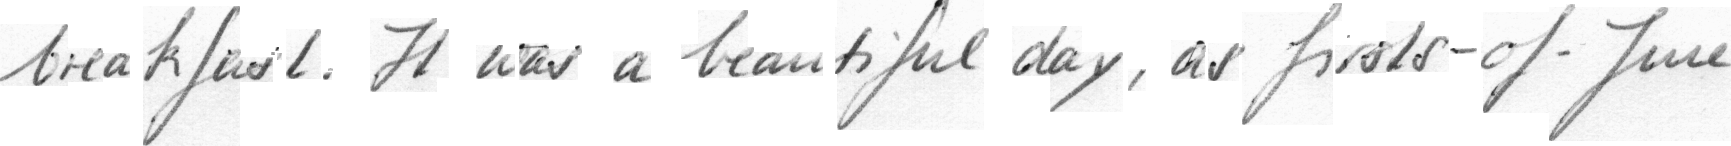

In [133]:
review_sample(124)

## 10. Reload Completed Manual Annotations

In [134]:
annotated_df = pd.read_csv(ANALYSIS_PATH)

# Count rows that have actually been categorized.
reviewed_mask = (
    annotated_df["error_category"]
    .fillna("")
    .str.strip()
    .ne("")
)

reviewed_df = annotated_df[reviewed_mask].copy()

print("Total selected :", len(annotated_df))
print("Reviewed       :", len(reviewed_df))
print("Remaining      :", len(annotated_df) - len(reviewed_df))

reviewed_df.head()


Total selected : 125
Reviewed       : 125
Remaining      : 0


,id,ground_truth,prediction,cer,wer,selection_group,error_category,image_quality,handwriting_difficulty,notes
0,p03-033-04,"suppose , to meet me for supper somewhere ? "" ...","Surname , is met at the ROH Superior Adventure...",0.603774,0.833333,high_cer,Character substitution;Word substitution,Good,Difficult,NaN
1,m04-038-04,Dinas Motor Omnibus Co. to ask what had happen...,"Dennis Hunter Dravides , her , Her wish that h...",0.578947,1.000000,high_cer,Character substitution;Word substitution;Punct...,Good,Difficult,NaN
2,p06-047-07,"his # prescription pad , and","his # # # if pressure script on paid , and",0.535714,1.166667,high_cer,Spacing;Character substitution;Word substitution,Good,Difficult,NaN
3,p02-022-04,laid his hand on hers . Gay smiled at him,David Luis blamed on Nero . Glory reunited out...,0.487805,0.700000,high_cer,Character substitution;Word substitution,Good,Difficult,NaN
4,p06-030-08,you are satisfied . ',"you are rats "" pedal .",0.428571,0.800000,high_cer,Character substitution;Word substitution;Punct...,cropping problems,Difficult,NaN


## 11. Generate Error-Category Summary

In [135]:
if reviewed_df.empty:
    print(
        "No manually categorized rows yet. "
        "Complete some annotations in the CSV and rerun this cell."
    )
    category_summary = pd.DataFrame(
        columns=["error_category", "count", "percentage"]
    )
else:
    categories = (
        reviewed_df["error_category"]
        .str.split(";")
        .explode()
        .str.strip()
    )

    categories = categories[categories.ne("")]

    category_summary = (
        categories
        .value_counts()
        .rename_axis("error_category")
        .reset_index(name="count")
    )

    # Multiple categories may be assigned to one sample,
    # so percentages can sum to more than 100%.
    category_summary["percentage"] = (
        category_summary["count"]
        / len(reviewed_df)
        * 100
    ).round(2)

category_summary


,error_category,count,percentage
0,Word substitution,72,57.6
1,Character substitution,62,49.6
2,Punctuation,24,19.2
3,Spacing,21,16.8
4,Capitalization,1,0.8


In [136]:
SUMMARY_PATH = RESULTS_DIR / "error_category_summary.csv"

category_summary.to_csv(SUMMARY_PATH, index=False)

print("Saved:")
print(SUMMARY_PATH)


Saved:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/results/exp002/error_category_summary.csv


## 12. Plot Error Categories

This plot is based on the manually reviewed **targeted diagnostic sample**, not all 638 failures. Because multiple labels are allowed, category counts may sum to more than the number of reviewed samples.


Figure saved to:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/results/exp002/figures/exp002_error_categories.png


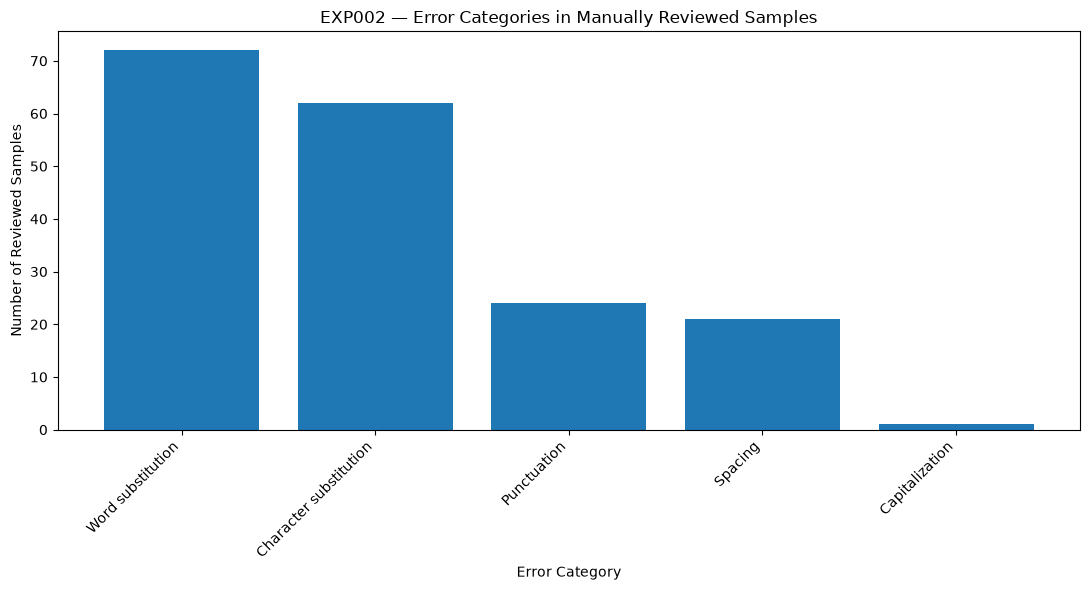

In [141]:
if category_summary.empty:
    print("No categories available to plot yet.")

else:
    plot_df = category_summary.sort_values(
        "count",
        ascending=False
    )

    # Create figures directory
    FIGURES_DIR = RESULTS_DIR / "figures"
    FIGURES_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    FIGURE_PATH = (
        FIGURES_DIR
        / "exp002_error_categories.png"
    )

    # Create chart
    plt.figure(figsize=(11, 6))

    plt.bar(
        plot_df["error_category"],
        plot_df["count"]
    )

    plt.title(
        "EXP002 — Error Categories in Manually Reviewed Samples"
    )

    plt.xlabel("Error Category")
    plt.ylabel("Number of Reviewed Samples")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.tight_layout()

    # IMPORTANT:
    # Save BEFORE plt.show()
    plt.savefig(
        FIGURE_PATH,
        dpi=300,
        bbox_inches="tight"
    )

    print("Figure saved to:")
    print(FIGURE_PATH)

    # Display after saving
    plt.show()

Figure 2 — Handwriting difficulty

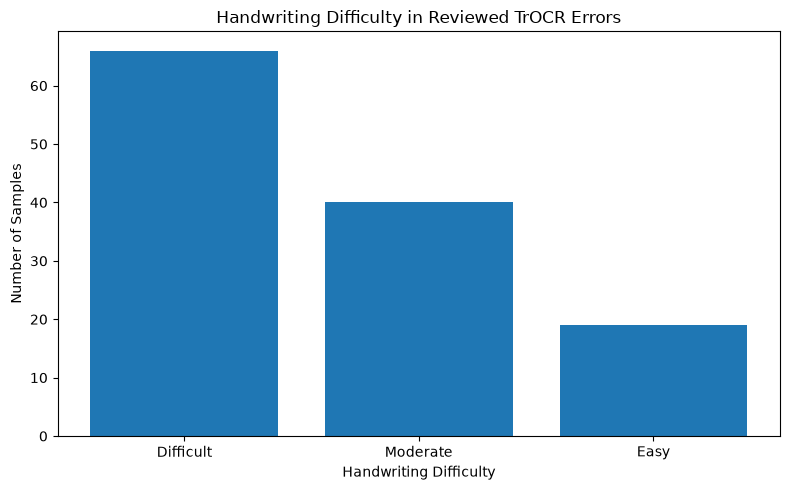

In [142]:
difficulty_counts = (
    reviewed_df["handwriting_difficulty"]
    .value_counts()
)

plt.figure(figsize=(8, 5))

plt.bar(
    difficulty_counts.index,
    difficulty_counts.values
)

plt.title(
    "Handwriting Difficulty in Reviewed TrOCR Errors"
)

plt.xlabel("Handwriting Difficulty")
plt.ylabel("Number of Samples")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "exp002_handwriting_difficulty.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 3 — Error category by sample group

In [145]:
# Figure 3 — Error category by diagnostic sample group

# Keep only the columns needed for this analysis
category_group_df = reviewed_df[
    ["error_category", "selection_group"]
].copy()

# Convert multiple categories into lists
category_group_df["error_category"] = (
    category_group_df["error_category"]
    .fillna("")
    .str.split(";")
)

# One row per error category
category_group_df = (
    category_group_df
    .explode("error_category")
    .reset_index(drop=True)
)

# Clean category names
category_group_df["error_category"] = (
    category_group_df["error_category"]
    .str.strip()
)

# Remove blank categories
category_group_df = category_group_df[
    category_group_df["error_category"] != ""
].copy()

# Create category × selection-group table
group_category_counts = pd.crosstab(
    index=category_group_df["error_category"],
    columns=category_group_df["selection_group"]
)

print(group_category_counts)

selection_group         high_cer  low_cer  random
error_category                                   
Capitalization                 0        1       0
Character substitution        25       15      22
Punctuation                   11        1      12
Spacing                        7        8       6
Word substitution             49        1      22



Figure saved to:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/results/exp002/figures/exp002_categories_by_group.png


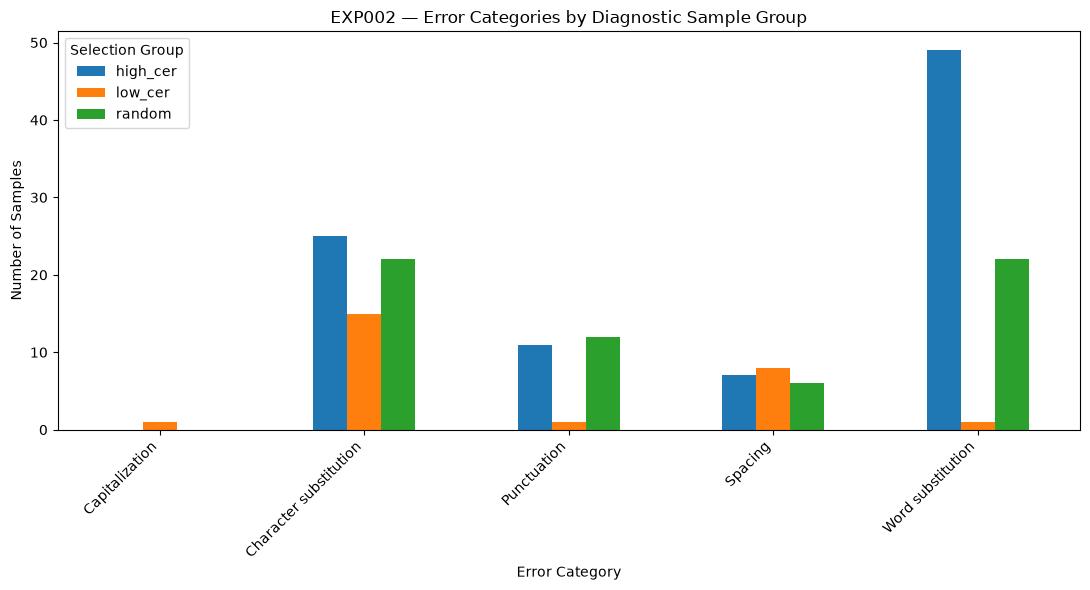

In [146]:
# Plot
ax = group_category_counts.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "EXP002 — Error Categories by Diagnostic Sample Group"
)

plt.xlabel("Error Category")
plt.ylabel("Number of Samples")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Selection Group"
)

plt.tight_layout()


# Save figure
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_PATH = (
    FIGURES_DIR
    / "exp002_categories_by_group.png"
)

# IMPORTANT: save before show
plt.savefig(
    FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

print()
print("Figure saved to:")
print(FIGURE_PATH)

plt.show()

## 13. Compare Selection Groups

In [140]:
if reviewed_df.empty:
    print("No reviewed samples available yet.")
else:
    group_summary = (
        reviewed_df
        .groupby("selection_group")
        .agg(
            reviewed_samples=("id", "count"),
            mean_cer=("cer", "mean"),
            mean_wer=("wer", "mean"),
        )
        .reset_index()
    )

    group_summary


## 14. Research Observations

### Dominant Error Categories

A total of 125 non-exact predictions were manually reviewed.

The most frequently observed error categories were:

| Error Category | Count | % of Reviewed Samples |
|---|---:|---:|
| Word substitution | 72 | 57.6% |
| Character substitution | 62 | 49.6% |
| Punctuation | 24 | 19.2% |
| Spacing | 21 | 16.8% |
| Capitalization | 1 | 0.8% |

Multiple categories could be assigned to a single prediction, so percentages do not sum to 100%.

The results indicate that word-level and character-level substitutions were the dominant recognition-error types in the manually reviewed diagnostic sample.

---

### High-CER Failures

Among the 50 highest-CER predictions:

- 49 contained word substitutions.
- 25 contained character substitutions.
- 11 contained punctuation errors.
- 7 contained spacing errors.

Handwriting difficulty was manually classified as:

- Difficult: 34
- Moderate: 13
- Easy: 3

Therefore, 68% of the highest-CER samples were judged to contain difficult handwriting.

This suggests an association between severe recognition failures and handwriting difficulty within the reviewed diagnostic sample.

However, this analysis does not establish that handwriting difficulty caused the recognition errors.

---

### Random Non-Exact Predictions

Among the 50 randomly selected non-exact predictions:

- 22 contained word substitutions.
- 22 contained character substitutions.
- 12 contained punctuation errors.
- 6 contained spacing errors.

This indicates that both word-level and character-level substitutions are also common among more typical non-exact predictions, rather than appearing only among the most severe failures.

---

### Low-CER but Non-Exact Predictions

Among the 25 lowest-CER non-exact predictions:

- 15 contained character substitutions.
- 8 contained spacing errors.
- 1 contained word substitution.
- 1 contained punctuation error.
- 1 contained a capitalization error.

This group demonstrates why Exact Match can be substantially lower than the overall CER might suggest.

Many low-CER predictions differ from the ground truth by only a small number of characters or formatting decisions, but these differences are still sufficient to cause Exact Match failure.

This is particularly relevant to structured-form fields such as IDs, dates, names, and account numbers, where even a single incorrect character may be significant.

---

### Handwriting Difficulty

Across all 125 manually reviewed samples:

- Difficult: 66 (52.8%)
- Moderate: 40 (32.0%)
- Easy: 19 (15.2%)

Most reviewed failures therefore occurred on handwriting classified as moderate or difficult.

The proportion of difficult handwriting was particularly high among the highest-CER group.

---

### Image Conditions

Most reviewed samples were not classified as having obvious image degradation.

A majority of samples were marked as having good image quality, while the main observed image issues were:

- cropping problems,
- blur,
- or combinations of these conditions.

This suggests that recognition failures cannot be attributed solely to poor image quality.

Consequently, generic image preprocessing should not automatically be assumed to improve TrOCR performance.

Controlled preprocessing experiments are required to determine whether particular transformations improve recognition.

---

### Implications for the Next Experiment

The error analysis suggests several possible intervention directions.

Character-level errors and visually difficult handwriting may potentially benefit from model adaptation or IAM-specific fine-tuning.

Cropping, blur, and other image-condition problems may potentially benefit from targeted preprocessing.

Spacing, punctuation, and capitalization errors may require normalization or task-specific evaluation rather than image enhancement.

Word substitutions and linguistically plausible predictions may warrant further investigation of the decoder and contextual behavior.

The next experiment should therefore test preprocessing in a controlled manner rather than applying multiple transformations simultaneously.

## 15. Limitations

- Only 125 of the 638 non-exact predictions are selected for initial manual review.
- The sample is deliberately stratified toward severe and minor errors.
- Therefore, category percentages from this analysis do **not** estimate natural category prevalence across all 638 failures.
- Multiple error categories may be assigned to a single prediction.
- Image-quality and handwriting-difficulty judgments are subjective manual annotations.
- `Possible language-generation error` is descriptive and does not establish decoder causality.

## Next Experiment

After completing this analysis, use the observed failure modes to design **EXP003 — Controlled Image Preprocessing**.

Develop preprocessing choices using the IAM validation split, then evaluate the selected approach on the held-out test split against the fixed EXP002 baseline:

- CER: 3.33%
- WER: 8.63%
- Exact Match: 56.89%
